In [1]:
pip install gym numpy matplotlib

/usr/local/lib/python3.11/dist-packages/gym/utils/passive_env_checker.py:241: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


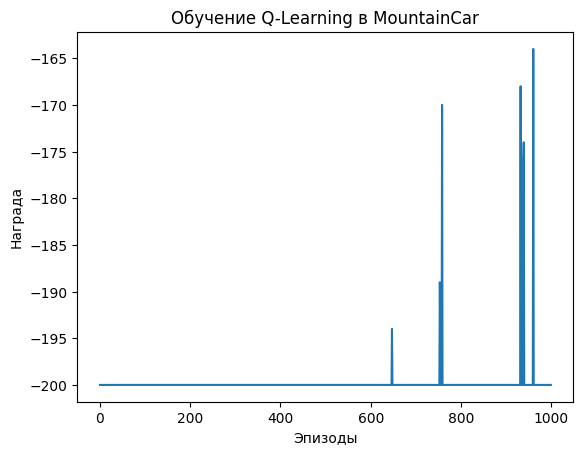

In [6]:
import gym
import numpy as np
import matplotlib.pyplot as plt

# Создаем среду MountainCar
env = gym.make("MountainCar-v0", render_mode=None)

ALPHA = 0.1        # Скорость обучения
GAMMA = 0.99       # Коэффициент дисконтирования будущих наград
EPSILON = 0.1      # Вероятность случайного действия
EPISODES = 1000    # Количество эпизодов для обучения
MAX_STEPS = 200    # Максимальная длина одного эпизода

state_space_bins = [24, 24]  # Количество интервалов для каждой из 2-х переменных состояния

# Создаем Q-таблицу (размер: [разбиение по позиции] x [разбиение по скорости] x [количество действий])
q_table = np.zeros(state_space_bins + [env.action_space.n])

# Определяем границы разбиения состояния
position_bins = np.linspace(-1.2, 0.6, state_space_bins[0] + 1)  # Разбиение позиции
velocity_bins = np.linspace(-0.07, 0.07, state_space_bins[1] + 1)  # Разбиение скорости

# Функция для преобразования непрерывного состояния в дискретное
def discretize_state(state):
    state = np.asarray(state).squeeze()  # Преобразуем в массив и убираем лишние измерения
    if state.ndim == 0:  # Если вдруг состояние оказалось скаляром, что не должно быть
        raise ValueError("Получено некорректное состояние среды, ожидается массив из 2 элементов.")

    discrete_state = (
        np.digitize(state[0], position_bins) - 1,  # Дискретизация позиции
        np.digitize(state[1], velocity_bins) - 1   # Дискретизация скорости
    )
    return discrete_state

# Функция для выбора действия по epsilon-greedy стратегии
def choose_action(state):
    if np.random.rand() < EPSILON:
        return np.random.choice(env.action_space.n)  # Случайное действие (исследование)
    else:
        return np.argmax(q_table[state])  # Действие с максимальным значением Q

# Список для хранения наград по эпизодам
reward_list = []

# Основной цикл обучения
for episode in range(EPISODES):
    state_info = env.reset()  # Сбрасываем среду
    state = state_info[0] if isinstance(state_info, tuple) else state_info  # Извлекаем состояние

    state = np.asarray(state).squeeze()  # Преобразуем в массив и убираем лишние измерения
    state = discretize_state(state)  # Дискретизируем состояние
    total_reward = 0  # Счетчик награды за эпизод

    for step in range(MAX_STEPS):
        action = choose_action(state)  # Выбираем действие
        next_state_info = env.step(action)  # Выполняем действие в среде

        # Извлекаем данные из ответа
        if len(next_state_info) == 4:
            next_state, reward, terminated, truncated = next_state_info
        else:
            next_state, reward, terminated, truncated, _ = next_state_info

        done = terminated or truncated  # Проверяем, завершен ли эпизод

        next_state = np.asarray(next_state).squeeze()  # Преобразуем в массив
        next_state = discretize_state(next_state)  # Дискретизируем следующее состояние

        # Обновляем Q-таблицу
        q_table[state][action] += ALPHA * (reward + GAMMA * np.max(q_table[next_state]) - q_table[state][action])
# Переходим в следующее состояние и суммируем награды
        state = next_state
        total_reward += reward

        if done:  # Если машина достигла цели или шаги закончились
            break

    reward_list.append(total_reward)  # Записываем суммарную награду за эпизод

plt.plot(range(EPISODES), reward_list)
plt.xlabel('Эпизоды')
plt.ylabel('Награда')
plt.title('Обучение Q-Learning в MountainCar')
plt.show()

env.close()